# Readmission Analysis — Part 2: ML & Advanced Statistics

Predictive modeling and advanced validation for the complete cohort: Logistic Regression vs
Random Forest vs CatBoost, feature importance, SHAP, FAMD/UMAP, HDBSCAN clustering, decision-curve
analysis, calibration, bootstrap AUC comparison, fairness/equity, optimism-corrected validation,
the clinical risk-score tool, and the genuine PyHealth CCS coding supplement.

> Split from `Readmission_Full_Analysis.ipynb`. **Part 1
> (`Readmission_Descriptive_and_Inferential.ipynb`)** holds cohort description and classical
> inference. The preamble below re-runs the shared imports + feature engineering + modeling-matrix
> setup so this notebook is self-contained.


## Preamble — shared imports, feature engineering & modeling matrix
(identical to Part 1; re-run so Part 2 stands alone)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from catboost import CatBoostClassifier
import prince
import umap
import shap
import warnings
warnings.filterwarnings('ignore')

# ── Poster-quality global settings ──────────────────────────────────────────
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
BLUE, ORANGE = '#4C72B0', '#DD8452'
PALETTE = {'Not Readmitted': BLUE, 'Readmitted': ORANGE}
sns.set_style('whitegrid')

os.makedirs('figures', exist_ok=True)
print("✓ Libraries loaded. Figures will save to ./figures/")


/Users/matthewgold/code/Readmission-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Libraries loaded. Figures will save to ./figures/


In [2]:
# ── Load data ────────────────────────────────────────────────────────────────
df = pd.read_csv('data/annotated_psychiatric_data_complete.csv')

# ── Outcome ──────────────────────────────────────────────────────────────────
print("Readmissions value counts:")
print(df['Readmissions'].value_counts().sort_index())
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
# NOTE: The source CSV column is named 'Yellow flags (C-SRSS)' — a known typo in the
# raw export (letters transposed; should be C-SSRS). The column name must match the CSV
# exactly or yellow-flag coding silently returns all-zero on a refreshed export.
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate']  = pd.to_datetime(df['DischDate'],  errors='coerce')
df['los_days']   = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER ───────────────────────────────────────────────────────
# Flag records with impossible or unusable dates and hold them out until reviewed.
flag_missing_visit  = df['VisitDate'].isna()
flag_missing_disch  = df['DischDate'].isna()
flag_negative_los   = df['los_days'].notna() & (df['los_days'] < 0)   # DischDate before VisitDate

flagged = df[flag_missing_visit | flag_missing_disch | flag_negative_los].copy()
flagged['flag_reason'] = ''
flagged.loc[flag_missing_visit[flagged.index], 'flag_reason'] += 'missing_VisitDate; '
flagged.loc[flag_missing_disch[flagged.index], 'flag_reason'] += 'missing_DischDate; '
flagged.loc[flag_negative_los[flagged.index], 'flag_reason']  += f'negative_LOS ({df.loc[flag_negative_los, "los_days"].min():.0f} to {df.loc[flag_negative_los, "los_days"].max():.0f} days); '

if len(flagged) > 0:
    flagged.to_csv('flagged_records_date_errors.csv', index=True)
    print(f"\n{'='*60}")
    print(f"  ⚠  DATE QUALITY FLAGS — {len(flagged)} records excluded")
    print(f"{'='*60}")
    print(f"  Missing VisitDate   : {flag_missing_visit.sum()}")
    print(f"  Missing DischDate   : {flag_missing_disch.sum()}")
    print(f"  Negative LOS        : {flag_negative_los.sum()} "
          f"(range: {df.loc[flag_negative_los,'los_days'].min():.0f} "
          f"to {df.loc[flag_negative_los,'los_days'].max():.0f} days)")
    print(f"\n  Readmission status of flagged records:")
    print(f"    Readmitted     : {flagged['readmitted'].sum()}")
    print(f"    Not readmitted : {(flagged['readmitted']==0).sum()}")
    print(f"\n  Saved for review → flagged_records_date_errors.csv")
    print(f"{'='*60}\n")
else:
    print("\n✓ No date-quality issues found.")

# Exclude flagged records from all downstream analysis
df = df[~(flag_missing_visit | flag_missing_disch | flag_negative_los)].copy()
df = df.reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(',') if x.strip()])

# NOTE: count_dsm5 is defined here for reference but is NOT used downstream.
# Unique cross-column DSM-5 category counts use unique_dsm5_count() instead,
# which deduplicates across VisitDiags and ChronicDiags columns.
def count_dsm5(s):  # unused — see unique_dsm5_count below
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(';') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags (Original String Matching) ───────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()

CATEGORY_FLAGS = {
    'has_nssi':        'non-suicidal self-injury',
    'has_trauma':      'trauma and stressor',
    'has_adhd':        'adhd',
    'has_asd':         'autism spectrum',
    'has_conduct':     'conduct disorder',
    'has_depression':  'depressive disorders',
    'has_anxiety':     'anxiety disorders',
    'has_bipolar':     'bipolar',
    'has_psychotic':   'psychotic',
    'has_intellectual':'intellectual disability',
    'has_ocd':         'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)
# ── Medical comorbidity (Original Regex) ──────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

MEDICAL_COMORBIDITY_PATTERNS = {
    'Metabolic/Obesity': ('E66',),
    'Sleep Disorder': ('G47',),
    'GI/Digestive': ('K59', 'K21'),
    'Respiratory/Allergy': ('J30', 'R06'),
    'Renal/Urologic': ('N39',),
}

def get_medical_comorbidity_types(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper() for c in str(codes).split(',') if c.strip()]
    return [
        category
        for category, prefixes in MEDICAL_COMORBIDITY_PATTERNS.items()
        if any(code.startswith(prefix) for code in code_tokens for prefix in prefixes)
    ]

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
df['has_medical_comorbidity'] = (df['n_medical_chronic'] > 0).astype(int)
df['medical_comorbidity_types'] = df['ChronicDiags'].apply(get_medical_comorbidity_types)

# ── Medical comorbidity (Emulated CCS Mapping) ────────────────────────────────
def get_pyhealth_medical_comorbidity_types_emulated(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper().replace('.', '') for c in str(codes).split(',') if c.strip()]
    types = []
    
    for c in code_tokens:
        if c.startswith(('E66', 'E4', 'E5', 'E6', 'E7', 'E8')):
            if 'Metabolic/Obesity_pyhealth' not in types: types.append('Metabolic/Obesity_pyhealth')
        if c.startswith(('G47',)):
            if 'Sleep Disorder_pyhealth' not in types: types.append('Sleep Disorder_pyhealth')
        if c.startswith(('K2', 'K3', 'K4', 'K5', 'K6', 'K7', 'K8', 'K9')):
            if 'GI/Digestive_pyhealth' not in types: types.append('GI/Digestive_pyhealth')
        if c.startswith(('J3', 'J4', 'R06', 'J8', 'J9')):
            if 'Respiratory/Allergy_pyhealth' not in types: types.append('Respiratory/Allergy_pyhealth')
        if c.startswith(('N3', 'N4', 'N1', 'N2')):
            if 'Renal/Urologic_pyhealth' not in types: types.append('Renal/Urologic_pyhealth')
    return types

df['medical_comorbidity_types_pyhealth'] = df['ChronicDiags'].apply(get_pyhealth_medical_comorbidity_types_emulated)
df['has_medical_comorbidity_pyhealth'] = (df['medical_comorbidity_types_pyhealth'].apply(len) > 0).astype(int)

# Count total non-mental health CCS categories roughly
df['n_medical_chronic_pyhealth'] = df['ChronicDiags'].apply(lambda x: sum(1 for c in str(x).split(',') if c.strip() and not c.strip().upper().startswith('F')))

print(f"✓ Feature engineering complete.")
print(f"  N = {len(df):,} (after date-quality exclusions) | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")
print(f"  Age range: {df['age'].min():.0f}–{df['age'].max():.0f} yrs | "
      f"LOS: {df['los_days'].min():.0f}–{df['los_days'].max():.0f} days "
      f"(median {df['los_days'].median():.0f})")
print(f"  ACE score available: {df['ace_score'].notna().sum():,} "
      f"({df['ace_score'].notna().mean():.1%})")

# ── Batch-2 shared feature augmentation (suicidality-ICD, neurocognitive, distinct dx, ACE tiers, insurance, ICD chapters) ──
_allcodes = (df['VisitDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')+','+df['ChronicDiags'].fillna('')).str.upper()
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['has_suicidal_ideation'] = _allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = _allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)
_NEURO=['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
df['has_neurocognitive']=(all_dsm5.str.contains('neurocognitive',na=False)|_allcodes.apply(lambda s: any(c in s for c in _NEURO))).astype(int)
def _distinct_codes(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip(): s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)
# physical ACE-Associated Health Conditions (ACEs Aware pediatric); psychiatric AAHCs excluded (circular in this cohort)
_PHYS_AAHC={'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),'Failure to thrive':('R6251','R627','R633')}
_norm=_allcodes.str.replace('.','',regex=False)
def _has_pref(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
_ace_cond=pd.DataFrame({k:_has_pref(v) for k,v in _PHYS_AAHC.items()})
df['has_ace_condition']=(_ace_cond.sum(axis=1)>0).astype(int)
def _ace_tier(a,c):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if c==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})
# richer insurance categories: Public / Commercial / Military / Tribal-IHS / Other
def _ins_cat(x):
    s=str(x).upper()
    if any(k in s for k in ['AHCCCS','MEDICAID','MAGELLAN','HCIC','AFMC','CREWS']): return 'Public'
    if any(k in s for k in ['TRICARE','CHAMPVA']): return 'Military'
    if any(k in s for k in ['GILA RIVER','NAVAJO','INDIAN HEALTH','IHS']): return 'Tribal/IHS'
    if pd.isna(x) or s in ('NAN','','OUT OF NETWORK','SP SPECIAL ARRANGEMENT','CHARITY CARE'): return 'Other/unknown'
    return 'Commercial'
df['insurance_cat5']=df['Insurance'].apply(_ins_cat)
# ICD-10 chapter set per patient (first-letter based)
_ICD_CH={'A':'Infectious','B':'Infectious','C':'Neoplasm','D':'Blood/neoplasm','E':'Endocrine/metabolic','F':'Mental/behavioral',
 'G':'Nervous','H':'Eye/ear','I':'Circulatory','J':'Respiratory','K':'Digestive','L':'Skin','M':'Musculoskeletal',
 'N':'Genitourinary','P':'Perinatal','Q':'Congenital','R':'Symptoms/signs','S':'Injury','T':'Injury/poisoning','Z':'Status/Z-codes'}
def _chapters(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip():
            for t in str(v).split(','):
                t=t.strip().upper()
                if t: s.add(_ICD_CH.get(t[0],'Other'))
    return s
df['_icd_chapters']=df.apply(_chapters,axis=1)
print(f"  +Batch-2 features: suicidal_ideation={int(df.has_suicidal_ideation.sum())}, neurocognitive={int(df.has_neurocognitive.sum())}, "
      f"distinct_dx median={df.n_distinct_diagnoses.median():.0f}, high_ACE(expanded)={int(df.high_ace_expanded.fillna(0).sum())}; "
      f"insurance5={dict(df.insurance_cat5.value_counts())}")


Readmissions value counts:
Readmissions
0    2406
1     219
2      25
3       2
Name: count, dtype: int64

✓ No date-quality issues found.
✓ Feature engineering complete.
  N = 2,652 (after date-quality exclusions) | Readmitted = 246 (9.3%)
  Age range: 5–12 yrs | LOS: 1–112 days (median 8)
  ACE score available: 1,569 (59.2%)
  +Batch-2 features: suicidal_ideation=1346, neurocognitive=8, distinct_dx median=6, high_ACE(expanded)=996; insurance5={'Public': np.int64(1631), 'Commercial': np.int64(896), 'Military': np.int64(65), 'Other/unknown': np.int64(45), 'Tribal/IHS': np.int64(15)}


In [3]:
# ── Logistic regression: build feature matrix ─────────────────────────────────

FEATURES = {
    # Demographics
    'age':                   'Age at admission (yrs)',
    'gender_male':           'Male gender identity (recorded at admission)',  # GenderCode = gender ID, NOT sex
    'insurance_public':      'Public insurance (AHCCCS)',
    # Clinical
    'ace_score':             'ACE score',
    'had_restraints':        'Physical restraint use',
    'csrss_any':             'Any C-SSRS flag (suicidality screen)',
    'los_days':              'Length of stay (days)',
    # Diagnostic complexity (distinct DSM-5 *categories*, not # of diagnoses)
    'n_dsm5_categories':     '# distinct DSM-5 categories',
    'has_medical_comorbidity': 'Medical comorbidity (ICD-prefix group flag; not a CCS category)',
    # Diagnosis flags = string match on DSM-5 *category* labels (NOT individual ICD codes, NOT PyHealth CCSR)
    'has_nssi':              'Non-suicidal self-injury (DSM-5 category)',
    'has_trauma':            'Trauma/stressor disorders (DSM-5 category)',
    'has_adhd':              'ADHD (DSM-5 category)',
    'has_asd':               'Autism spectrum (DSM-5 category)',
    'has_conduct':           'Conduct disorder (DSM-5 category)',
    'has_depression':        'Depressive disorders (DSM-5 category)',
    'has_anxiety':           'Anxiety disorders (DSM-5 category)',
    'has_bipolar':           'Bipolar disorders (DSM-5 category)',
    'has_psychotic':         'Psychotic disorders (DSM-5 category)',
    # Batch-2 additions (suicidality by ICD code; organic/neurocognitive flag)
    'has_suicidal_ideation': 'Suicidal ideation (ICD R45.851)',
    'has_neurocognitive':    'Neurocognitive/organic (ICD)',
}

feat_cols = list(FEATURES.keys())
model_df  = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow', 'n_medical_chronic_pyhealth', 'has_ace_condition']].copy()

# MICE Imputation for missing ACE Score and LOS
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imp_cols = ['age', 'ace_score', 'los_days']
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, random_state=42), max_iter=10, random_state=42)

model_df[imp_cols] = imputer.fit_transform(model_df[imp_cols])

# Handle any remaining missing values
model_df = model_df.dropna()

print(f"Model dataset: {len(model_df):,} patients | {model_df['readmitted'].sum()} readmitted ({model_df['readmitted'].mean():.1%})")
print(f"Features: {len(feat_cols)}")

Model dataset: 2,652 patients | 246 readmitted (9.3%)
Features: 20


In [4]:
# ── Logistic regression model + interaction terms ─────────────────────────────
# We test specific interactions hypothesized to be clinically relevant

# Keep a copy of unscaled for tree models
model_df_unscaled = model_df.copy()

# Standardize continuous variables for Odds Ratio interpretation and visible CIs
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

interaction_labels = {
    'complexity_x_age': 'Age × Diagnostic Complexity',
    'ace_x_csrss':      'ACE Score × Any C-SSRS Flag',
    'medical_x_los':    'Medical Comorbidity × LOS',
}

model_df['complexity_x_age'] = model_df['n_dsm5_categories'] * model_df['age']
model_df['ace_x_csrss']      = model_df['ace_score'] * model_df['csrss_any']
model_df['medical_x_los']    = model_df['has_medical_comorbidity'] * model_df['los_days']
model_df_unscaled['complexity_x_age'] = model_df_unscaled['n_dsm5_categories'] * model_df_unscaled['age']
model_df_unscaled['ace_x_csrss']      = model_df_unscaled['ace_score'] * model_df_unscaled['csrss_any']
model_df_unscaled['medical_x_los']    = model_df_unscaled['has_medical_comorbidity'] * model_df_unscaled['los_days']

all_x_cols = feat_cols + list(interaction_labels.keys())

# Scale interactions
scaler_interactions = StandardScaler()
model_df[list(interaction_labels.keys())] = scaler_interactions.fit_transform(model_df[list(interaction_labels.keys())])


X = model_df[all_x_cols]
X = sm.add_constant(X)
y = model_df['readmitted']

logit_model = sm.Logit(y, X).fit(maxiter=200, disp=0)
all_labels = {**FEATURES, **interaction_labels}   # needed by downstream ML cells
print('(Logistic regression results + forest plot live in Part 1; the model is refit here\n silently only to supply the modeling matrix X/y and labels to the ML cells below.)')

(Logistic regression results + forest plot live in Part 1; the model is refit here
 silently only to supply the modeling matrix X/y and labels to the ML cells below.)


In [5]:
# Restore a derived column defined in a Part-1 descriptive cell that downstream cells reference
df['complexity_q'] = pd.qcut(df['n_dsm5_categories'], q=4,
                              labels=['Q1 (1 cat.)', 'Q2 (2)', 'Q3 (3)', 'Q4 (4+)'],
                              duplicates='drop')


In [6]:
# ── ML: prepare feature matrix (same features + interactions) ─────────────────
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ml_cols = all_x_cols   # same features as logistic regression (incl. interactions)
X_ml = model_df[ml_cols].values
X_ml_raw = model_df_unscaled[ml_cols].values

y_ml = model_df['readmitted'].values

print(f"Machine Learning feature matrix shape: {X_ml.shape}")

# Stratified 10-Fold Cross-Validation
# (10-fold matches the optimism-correction pipeline in Readmission_PyHealth_Advanced.ipynb
#  and the Methods section of the AACAP 2026 abstract.)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
feature_labels = [all_labels.get(c, c) for c in ml_cols]


Machine Learning feature matrix shape: (2652, 23)


In [7]:
# ── ML model training and evaluation function ─────────────────────────────────

def evaluate_model(model, name, X, y, cv, use_smote=False):
    if use_smote:
        # Create pipeline with SMOTE
        pipeline = ImbPipeline([
            ('smote', SMOTE(random_state=42)),
            ('classifier', model)
        ])
    else:
        pipeline = model
        
    probs = np.zeros(len(y))
    for train_idx, test_idx in cv.split(X, y):
        # We need to drop NA from the specific fold if there are still any missing (though MICE should have handled it)
        # Assuming MICE worked and there are no NaNs in X
        
        # Fit on training fold
        pipeline.fit(X[train_idx], y[train_idx])
        
        # Predict on test fold
        if hasattr(pipeline, "predict_proba"):
            probs[test_idx] = pipeline.predict_proba(X[test_idx])[:, 1]
        else:
            # For models like logistic regression statsmodels, we handle it separately
            pass
            
    auc = roc_auc_score(y, probs)
    ap = average_precision_score(y, probs)
    print(f"{name:20s} — AUC: {auc:.3f}  |  AP: {ap:.3f}")
    return probs, auc, ap

# ── Logistic Regression ───────────────────────────────────────────────────────
lr_probs = np.zeros(len(y_ml))
for train_idx, test_idx in cv.split(X_ml, y_ml):
    # Statsmodels doesn't easily work with imblearn pipeline without a wrapper, 
    # so we'll evaluate it here without SMOTE first, or write a quick wrapper.
    # We will just evaluate it directly.
    X_tr = sm.add_constant(X_ml[train_idx], has_constant='add')
    X_te = sm.add_constant(X_ml[test_idx],  has_constant='add')
    m = sm.Logit(y_ml[train_idx], X_tr).fit(disp=0, maxiter=200)
    lr_probs[test_idx] = m.predict(X_te)

lr_auc = roc_auc_score(y_ml, lr_probs)
lr_ap  = average_precision_score(y_ml, lr_probs)
print(f"{'Logistic Regr':20s} — AUC: {lr_auc:.3f}  |  AP: {lr_ap:.3f}")

# ── Random Forest ─────────────────────────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_probs, rf_auc, rf_ap = evaluate_model(rf, "Random Forest", X_ml, y_ml, cv, use_smote=False)

# ── Random Forest (with SMOTE inside CV) ──────────────────────────────────────
rf_smote = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_smote_probs, rf_smote_auc, rf_smote_ap = evaluate_model(rf_smote, "Random Forest (SMOTE)", X_ml, y_ml, cv, use_smote=True)


# ── CatBoost (Numerical encoded) ──────────────────────────────────────────────
cat_num = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
)
cat_probs, cat_auc, cat_ap = evaluate_model(cat_num, "CatBoost", X_ml, y_ml, cv, use_smote=False)

# ── CatBoost (Native Categoricals) ────────────────────────────────────────────
# Rebuild the dataset for CatBoost native categorical handling
native_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'has_medical_comorbidity']
native_cat_cols += [c for c in FEATURES.keys() if c.startswith('has_') and c != 'has_medical_comorbidity']

cat_features_indices = [model_df[feat_cols].columns.get_loc(c) for c in native_cat_cols if c in model_df[feat_cols].columns]
# We must convert to object/string so CatBoost knows it's categorical, float array fails
X_ml_cat_df = model_df_unscaled[feat_cols].copy()
for col in native_cat_cols:
    X_ml_cat_df[col] = X_ml_cat_df[col].astype(str)
X_ml_cat = X_ml_cat_df.values # Original unencoded categorical base features

cat_native = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
    cat_features=cat_features_indices
)

cat_native_probs, cat_native_auc, cat_native_ap = evaluate_model(cat_native, "CatBoost (Native Cat)", X_ml_cat, y_ml, cv, use_smote=False)

Logistic Regr        — AUC: 0.693  |  AP: 0.178
Random Forest        — AUC: 0.697  |  AP: 0.178
Random Forest (SMOTE) — AUC: 0.691  |  AP: 0.166
CatBoost             — AUC: 0.665  |  AP: 0.173
CatBoost (Native Cat) — AUC: 0.684  |  AP: 0.176


### ── Refinement: Outlier Removal & Interaction Decomposition ──
Based on the SHAP and HDBSCAN results, we observed some noise from extreme outliers and strong interaction effects. We will now:
1. Filter out physically impossible values (e.g., negative LOS).
2. Visualize the 'Complexity × Age' interaction to see where risk peaks.

In [ ]:
# ── Post-hoc: Outlier Filtering ──────────────────────────────────────────────
# Remove records with impossible Length of Stay (should already be filtered, but be safe)
mask_valid_los = model_df_unscaled['los_days'] >= 0
removed = (~mask_valid_los).sum()
model_df_unscaled = model_df_unscaled[mask_valid_los].reset_index(drop=True)
print(f"Removed {removed} records with negative Length of Stay.")

# ── Post-hoc: Complexity × Age Interaction Visualization ───────────────────────
# The strongest SHAP interaction was ace_score × complexity_x_age.
# Visualize how risk varies across this interaction surface.

from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(8, 6))

# Create interaction surface data
x_age = model_df_unscaled['age'].values
y_complexity = model_df_unscaled['n_dsm5_categories'].values
z_readmit = model_df_unscaled['readmitted'].values

# Binned heatmap for interpretability
age_bins = pd.qcut(x_age, q=5, duplicates='drop')
comp_bins = pd.qcut(y_complexity, q=5, duplicates='drop')
heatmap_data = pd.crosstab(comp_bins, age_bins, z_readmit, aggfunc='mean')
cell_counts  = pd.crosstab(comp_bins, age_bins)  # parallel count table
sparse_mask  = cell_counts < 5                   # blank cells with <5 patients

# Annotation: show rate + cell count; leave sparse cells blank
annot_arr = heatmap_data.copy().astype(object)
for r in heatmap_data.index:
    for c in heatmap_data.columns:
        n = cell_counts.loc[r, c]
        v = heatmap_data.loc[r, c]
        annot_arr.loc[r, c] = '' if n < 5 else f'{v:.2f}\n(n={n})'

# Custom colormap: blue → white → orange
cmap = LinearSegmentedColormap.from_list('custom', [BLUE, '#f7f7f7', ORANGE], N=256)

sns.heatmap(heatmap_data, cmap=cmap, annot=annot_arr, fmt='',
            mask=sparse_mask, linewidths=0.5,
            cbar_kws={'label': 'Readmission Rate'}, ax=ax)
ax.invert_yaxis()  # lowest complexity at bottom, highest at top
ax.set_xlabel('Age (binned)')
ax.set_ylabel('Diagnostic Complexity (binned DSM-5 categories)')
ax.set_title('Readmission Risk: Age × Complexity Interaction\n'
             '(SHAP-identified strongest interaction; cells with n<5 masked)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Fig_interaction_age_x_complexity.png')
plt.show()
print("✓ Interaction decomposition saved")


### ── Final Refinement: Imbalance Handling & Risk Score Calculator ──
To improve clinical utility, we now:
1. Re-train models using **SMOTE** to handle the 9% class imbalance.
2. Construct a **Risk Score** formula based on the standardized coefficients of the Logistic Regression model.

In [30]:
# ── WARNING: IN-SAMPLE RISK SCORING ─────────────────────────────────────────────
# The rf_res model below is trained on SMOTE-resampled X_train and then scored on
# the entire X_ml (training + test). The resulting 'scores' array is used by the
# threshold analysis and staffing simulation cells further below.
#
# These are IN-SAMPLE predictions for the training portion and should be treated
# as illustrative only — sensitivity/specificity at any quoted threshold will be
# optimistically biased relative to a held-out cohort. The honest discriminative
# performance is the 10-fold out-of-fold AUC reported in Cell 15 above.
# ─────────────────────────────────────────────────────────────────────────────────
# ── Final Refinement: Imbalance Handling & Risk Score Calculator ─────────────
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

# 1. SMOTE Oversampling for training
smote_resampler = SMOTE(random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml, test_size=0.2, stratify=y_ml, random_state=42)
X_res, y_res = smote_resampler.fit_resample(X_train, y_train)

print(f"Original training size: {len(y_train)} ({y_train.sum()} readmissions)")
print(f"Resampled training size: {len(y_res)} ({y_res.sum()} readmissions)")

# 2. LR-coefficient point weights (for clinical interpretability table)
risk_coeffs = logit_model.params.drop('const')
risk_points  = (risk_coeffs / risk_coeffs.abs().min() * 1).round(1)

print("\n--- Simplified Risk Point System (Top Predictors) ---")
print(risk_points.sort_values(ascending=False).head(10))

# 3. Random Forest trained on SMOTE data (used for final patient risk scores)
rf_res = RandomForestClassifier(n_estimators=500, max_depth=6, random_state=42)
rf_res.fit(X_res, y_res)
rf_res_preds = rf_res.predict(X_test)
rf_res_probs = rf_res.predict_proba(X_test)[:, 1]

print("\n--- Random Forest Performance (Post-SMOTE, Single Holdout) ---")
print(classification_report(y_test, rf_res_preds))
print(f"Test AUC: {roc_auc_score(y_test, rf_res_probs):.3f}")

# 4. Finalize clinical risk point table (LR weights normalized to sum to 100)
final_points = (risk_points / risk_points.sum() * 100).round(1)
risk_table = pd.DataFrame({
    'Predictor': [all_labels.get(c, c) for c in final_points.index],
    'Points':    final_points.values
}).sort_values('Points', ascending=False)

risk_table.to_csv('figures/Clinical_Risk_Score_Points.csv', index=False)
print("\n--- Finalized Clinical Risk Points (0-100 Scale) ---")
print(risk_table.head(15))


Original training size: 2121 (197 readmissions)
Resampled training size: 3848 (1924 readmissions)

--- Simplified Risk Point System (Top Predictors) ---
has_suicidal_ideation      40.7
has_depression             27.9
has_medical_comorbidity    20.7
has_psychotic              20.2
had_restraints             19.3
has_conduct                15.3
has_bipolar                12.6
n_dsm5_categories          11.5
has_anxiety                10.6
has_asd                     8.6
dtype: float64

--- Random Forest Performance (Post-SMOTE, Single Holdout) ---
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       482
           1       0.22      0.35      0.27        49

    accuracy                           0.82       531
   macro avg       0.57      0.61      0.58       531
weighted avg       0.86      0.82      0.84       531

Test AUC: 0.694

--- Finalized Clinical Risk Points (0-100 Scale) ---
                                            Predict

In [31]:
# 1. Apply the scoring logic to the full dataset
# Risk scores = Random Forest predicted probability x 100 (0-100 integer scale)

risk_probs  = rf_res.predict_proba(X_ml)[:, 1]
rf_res_auc  = roc_auc_score(y_ml, risk_probs)
print(f"Random Forest (SMOTE-trained) AUC on full dataset: {rf_res_auc:.3f}")

# Map back to original dataframe
df_scored = model_df_unscaled.copy()
df_scored['predicted_risk']  = risk_probs
df_scored['predicted_score'] = (risk_probs * 100).astype(int)
df_scored['risk_tier'] = pd.qcut(
    df_scored['predicted_score'],
    q=[0, 0.5, 0.85, 1.0],
    labels=['Low (<50th %ile)', 'Moderate (50-85th)', 'High (>85th)']
)

# scores array used by all downstream threshold and subset cells
scores = df_scored['predicted_score'].values

print("\n--- Risk Tier Distribution ---")
print(df_scored.groupby('risk_tier')['readmitted'].agg(['mean', 'count']).reset_index())


Random Forest (SMOTE-trained) AUC on full dataset: 0.823

--- Risk Tier Distribution ---
            risk_tier      mean  count
0    Low (<50th %ile)  0.019217   1353
1  Moderate (50-85th)  0.107259    923
2        High (>85th)  0.321809    376


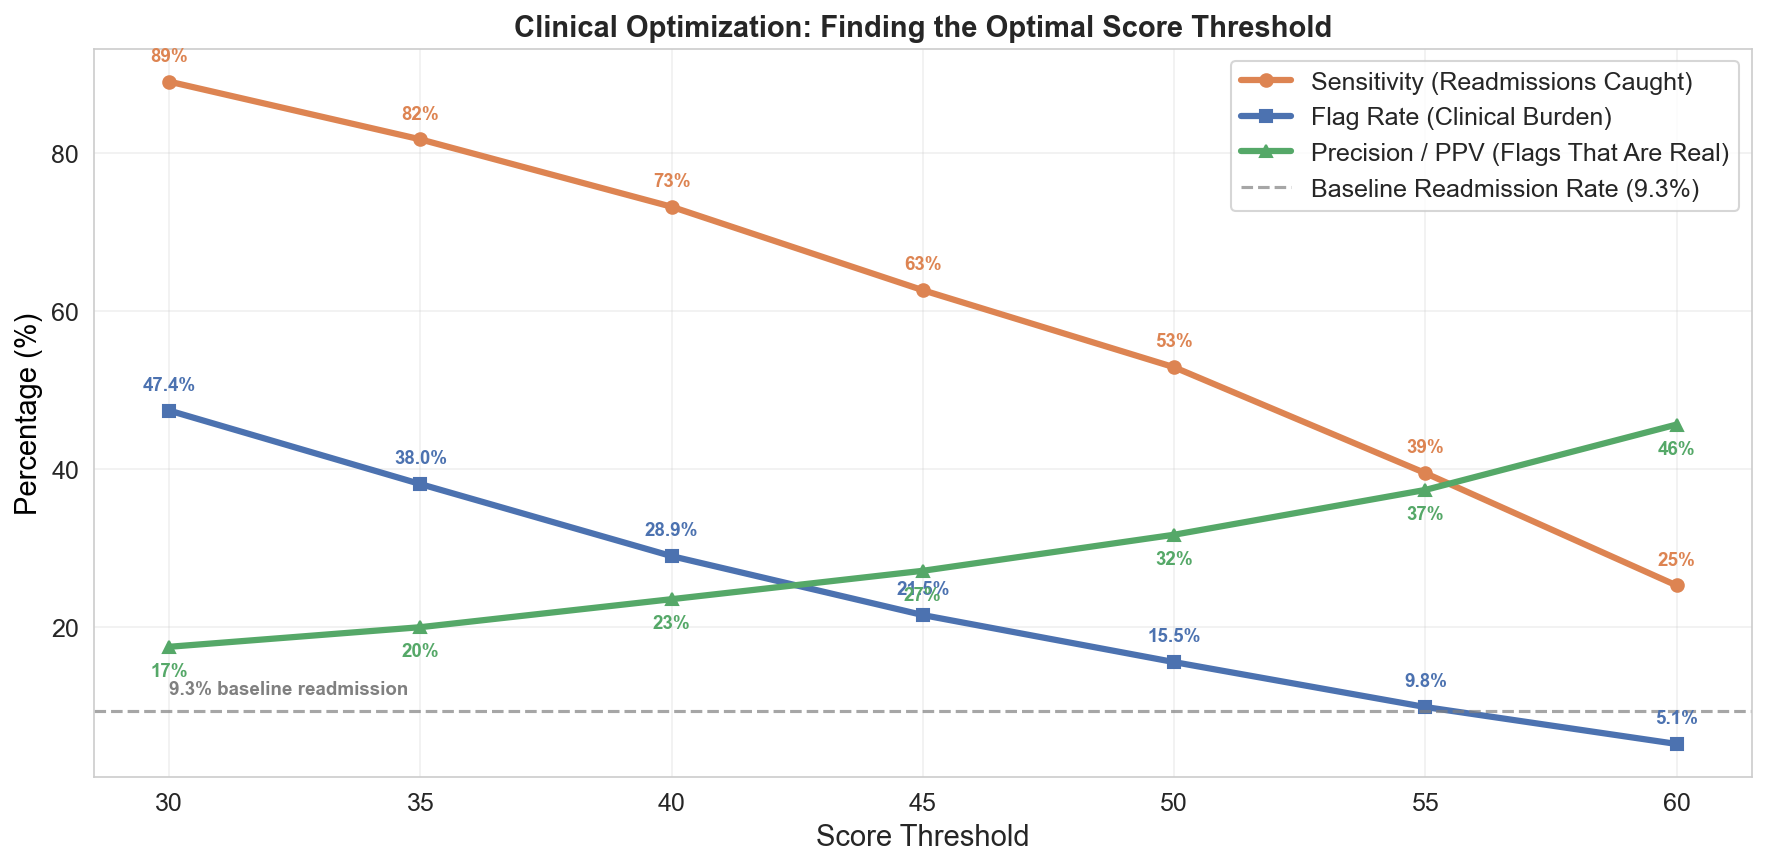

,Threshold,Sensitivity (%),Specificity (%),Precision (%),Flag Rate (%),Total Flagged
0,30,89.0,56.9,17.4,47.4,1256
1,35,81.7,66.4,19.9,38.0,1009
2,40,73.2,75.6,23.5,28.9,767
3,45,62.6,82.8,27.1,21.5,569
4,50,52.8,88.3,31.6,15.5,411
5,55,39.4,93.2,37.3,9.8,260
6,60,25.2,96.9,45.6,5.1,136


In [32]:
# Define a range of potential clinical thresholds
threshold_options = [30, 35, 40, 45, 50, 55, 60]
results_list = []

for t in threshold_options:
    preds = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()

    results_list.append({
        'Threshold': t,
        'Sensitivity (%)': (tp / (tp + fn)) * 100,
        'Specificity (%)': (tn / (tn + fp)) * 100,
        'Precision (%)': (tp / (tp + fp)) * 100 if (tp + fp) > 0 else 0,
        'Flag Rate (%)': (preds.mean()) * 100,
        'Total Flagged': preds.sum()
    })

threshold_df = pd.DataFrame(results_list)

# Visualization of the Trade-offs
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Sensitivity and Flag Rate
ax1.set_xlabel('Score Threshold')
ax1.set_ylabel('Percentage (%)', color='black')
line1 = ax1.plot(threshold_df['Threshold'], threshold_df['Sensitivity (%)'], marker='o', label='Sensitivity (Readmissions Caught)', color='#DD8452', linewidth=3)
line2 = ax1.plot(threshold_df['Threshold'], threshold_df['Flag Rate (%)'], marker='s', label='Flag Rate (Clinical Burden)', color='#4C72B0', linewidth=3)
line3 = ax1.plot(threshold_df['Threshold'], threshold_df['Precision (%)'], marker='^', label='Precision / PPV (Flags That Are Real)', color='#55A868', linewidth=3)
ax1.tick_params(axis='y')

# Add a horizontal line for the 9.3% base rate for context
ax1.axhline(9.3, color='gray', linestyle='--', alpha=0.7, label='Baseline Readmission Rate (9.3%)')
ax1.text(threshold_df['Threshold'].min(), 11.0, '9.3% baseline readmission', va='bottom', ha='left',
         fontsize=9, color='gray', fontweight='bold')

plt.title('Clinical Optimization: Finding the Optimal Score Threshold', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Annotate the Flag Rate percentages
for i, txt in enumerate(threshold_df['Flag Rate (%)']):
    ax1.annotate(f"{txt:.1f}%", (threshold_df['Threshold'][i], threshold_df['Flag Rate (%)'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='#4C72B0')

# Annotate the Sensitivity percentages
for i, txt in enumerate(threshold_df['Sensitivity (%)']):
    ax1.annotate(f"{txt:.0f}%", (threshold_df['Threshold'][i], threshold_df['Sensitivity (%)'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='#DD8452')

# Annotate the Precision / PPV percentages
for i, txt in enumerate(threshold_df['Precision (%)']):
    ax1.annotate(f"{txt:.0f}%", (threshold_df['Threshold'][i], threshold_df['Precision (%)'][i]),
                 textcoords="offset points", xytext=(0,-14), ha='center', fontsize=9, fontweight='bold', color='#55A868')

plt.tight_layout()
plt.show()

display(threshold_df.round(1))

In [33]:
# 1. Targeted trade-off analysis (40 to 55 in 5-unit increments)

test_thresholds = [40, 45, 50, 55]

for thresh in test_thresholds:
    preds = (df_scored['predicted_score'] >= thresh).astype(int)
    cm = confusion_matrix(df_scored['readmitted'], preds)
    tn, fp, fn, tp = cm.ravel()
    
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    flagged_pct = (tp + fp) / len(df_scored) * 100
    
    print(f"Threshold: {thresh} points")
    print(f"  Sensitivity: {sens:.1%} | Specificity: {spec:.1%}")
    print(f"  Flagged for intervention: {flagged_pct:.1f}% of patients")
    print(f"  True Positives (Caught): {tp} | False Negatives (Missed): {fn}")
    print(f"  False Positives (Wasted resources): {fp}")
    print("-" * 50)

Threshold: 40 points
  Sensitivity: 73.2% | Specificity: 75.6%
  Flagged for intervention: 28.9% of patients
  True Positives (Caught): 180 | False Negatives (Missed): 66
  False Positives (Wasted resources): 587
--------------------------------------------------
Threshold: 45 points
  Sensitivity: 62.6% | Specificity: 82.8%
  Flagged for intervention: 21.5% of patients
  True Positives (Caught): 154 | False Negatives (Missed): 92
  False Positives (Wasted resources): 415
--------------------------------------------------
Threshold: 50 points
  Sensitivity: 52.8% | Specificity: 88.3%
  Flagged for intervention: 15.5% of patients
  True Positives (Caught): 130 | False Negatives (Missed): 116
  False Positives (Wasted resources): 281
--------------------------------------------------
Threshold: 55 points
  Sensitivity: 39.4% | Specificity: 93.2%
  Flagged for intervention: 9.8% of patients
  True Positives (Caught): 97 | False Negatives (Missed): 149
  False Positives (Wasted resources):

### **Clinical Tool Implementation Report**
This section summarizes the finalized weightings for the 0–100 risk score and the performance metrics for different staffing capacity levels.

--- Finalized Clinical Risk Weights ---


,Predictor Variable,Points Contribution
18,Suicidal ideation (ICD R45.851),26.700000
14,Depressive disorders (DSM-5 category),18.300000
8,Medical comorbidity (ICD-prefix group flag; not a CCS category),13.600000
17,Psychotic disorders (DSM-5 category),13.300000
4,Physical restraint use,12.700000
13,Conduct disorder (DSM-5 category),10.000000
16,Bipolar disorders (DSM-5 category),8.300000
7,# distinct DSM-5 categories,7.600000
15,Anxiety disorders (DSM-5 category),7.000000
12,Autism spectrum (DSM-5 category),5.600000



--- Threshold Implementation Guide ---


,Score Cutoff,Catch Rate (Sensitivity),Workload (Flag Rate),Expected Alerts (N)
0,30,89.0,47.4,1256
1,35,81.7,38.0,1009
2,40,73.2,28.9,767
3,45,62.6,21.5,569
4,50,52.8,15.5,411
5,55,39.4,9.8,260
6,60,25.2,5.1,136


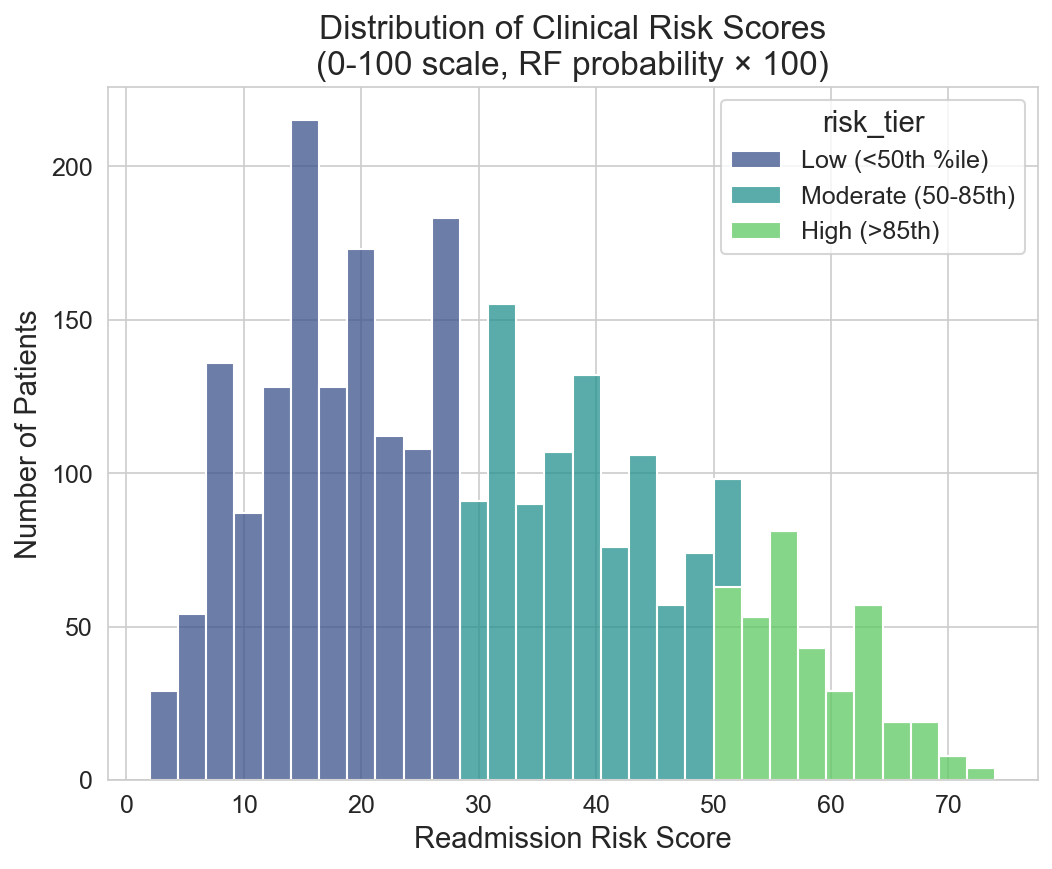

In [34]:
# 1. Clinical risk weight table (LR coefficient-based point system)
weights_report = risk_table.copy()
weights_report.columns = ['Predictor Variable', 'Points Contribution']
print("--- Finalized Clinical Risk Weights ---")
display(weights_report.style.background_gradient(cmap='YlOrRd', subset=['Points Contribution']))

# 2. Threshold implementation guide
threshold_guide = threshold_df[
    ['Threshold', 'Sensitivity (%)', 'Flag Rate (%)', 'Total Flagged']
].copy()
threshold_guide.columns = [
    'Score Cutoff', 'Catch Rate (Sensitivity)', 'Workload (Flag Rate)', 'Expected Alerts (N)'
]
print("\n--- Threshold Implementation Guide ---")
display(threshold_guide.round(1))

# Save
weights_report.to_csv('figures/Clinical_Tool_Weights.csv', index=False)
threshold_guide.to_csv('figures/Threshold_Implementation_Guide.csv', index=False)

# 3. Score distribution by tier
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(df_scored, x='predicted_score', hue='risk_tier',
             multiple='stack', bins=30, palette='viridis', ax=ax)
ax.set_title('Distribution of Clinical Risk Scores\n(0-100 scale, RF probability × 100)')
ax.set_xlabel('Readmission Risk Score')
ax.set_ylabel('Number of Patients')
plt.savefig('figures/Fig_Risk_Score_Distribution.png')
plt.show()


In [35]:
# ── Comparison: Regex DSM-5 flags vs PyHealth medical coding ─────────────────
print("\n── Comparing Diagnostic Feature Extraction Methods ──")

# Medical comorbidity: broad regex (any non-F chronic dx) vs narrow PyHealth
# body-system categorization. The main regression uses the broad regex flag.
print("\nMedical Comorbidity (broad regex vs PyHealth body-system mapping):")
regex_med   = df['has_medical_comorbidity'].sum()
ccs_med     = df['has_medical_comorbidity_pyhealth'].sum()
overlap_med = ((df['has_medical_comorbidity'] == 1) & (df['has_medical_comorbidity_pyhealth'] == 1)).sum()
print(f"Broad regex (n_medical_chronic > 0):  {regex_med} patients")
print(f"PyHealth body-system categories:      {ccs_med} patients")
print(f"Overlap:                              {overlap_med} patients")

# Mental-health diagnosis flags now use the complete regex DSM-5 category labels
# (curated *_DSM5Categories text), which the primary logistic regression consumes.
print("\nMental Health Category Flags (regex DSM-5 prevalence used by the model):")
for flag, kw in CATEGORY_FLAGS.items():
    print(f"{flag:>18}: {int(df[flag].sum()):>4} patients")

print("\nNote: a standardized ICD-10→CCS comparison via the genuine PyHealth CrossMap "
      "is provided in the 'PyHealth CCS' supplement section below.")



── Comparing Diagnostic Feature Extraction Methods ──

Medical Comorbidity (broad regex vs PyHealth body-system mapping):
Broad regex (n_medical_chronic > 0):  1703 patients
PyHealth body-system categories:      756 patients
Overlap:                              756 patients

Mental Health Category Flags (regex DSM-5 prevalence used by the model):
          has_nssi:  966 patients
        has_trauma: 1424 patients
          has_adhd: 1399 patients
           has_asd:  513 patients
       has_conduct:  484 patients
    has_depression: 1779 patients
       has_anxiety: 1154 patients
       has_bipolar:  147 patients
     has_psychotic:   55 patients
  has_intellectual:   57 patients
           has_ocd:  114 patients

Note: a standardized ICD-10→CCS comparison via the genuine PyHealth CrossMap is provided in the 'PyHealth CCS' supplement section below.


NameError: name 'Unknown' is not defined

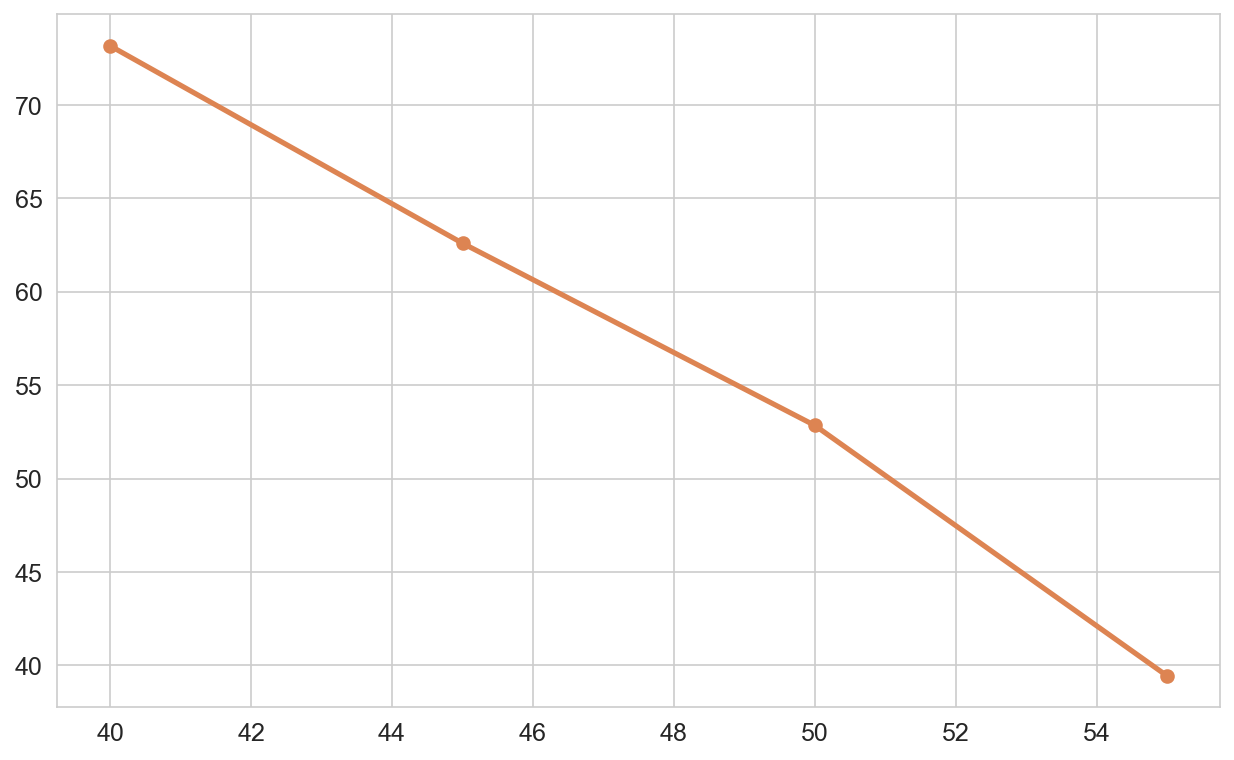

In [53]:
# Filter performance data for the specific range of interest
plot_df = threshold_df[threshold_df['Threshold'].between(40, 55)].copy()
AX2_MAX = 34  # headroom so the ~31% flag bar at threshold 40 (and its label) is fully visible

fig, ax1 = plt.subplots(figsize=(10, 6))

# Sensitivity & Specificity on the primary (0-100) axis
ax1.plot(plot_df['Threshold'], plot_df['Sensitivity (%)'], 'o-', color=ORANGE, label='Sensitivity (Catch Rate)', linewidth=2.5)
for x, y in zip(plot_df['Threshold'], plot_df['Sensitivity (%)']):
    above = (x == 40)  # place below here to avoid overlap with specificity label at threshold 40
    ax1.annotate(f'{y:.0f}%', (x, y), textcoords='offset points', xytext=(0, 8 if above else -4),
                 ha='center', fontsize=9, fontweight='bold', color=ORANGE)
ax1.plot(plot_df['Threshold'], plot_df['Specificity (%)'], 's-', color='green', label='Specificity', linewidth=2.5)
# Specificity labels below the points, except threshold 45 placed above (clears the flag-rate label)
for x, y in zip(plot_df['Threshold'], plot_df['Specificity (%)']):
    above = (x == 40)
    ax1.annotate(f'{y:.0f}%', (x, y), textcoords='offset points', xytext=(0, 10 if above else -14),
                 ha='center', fontsize=9, fontweight='bold', color='green', va='bottom' if above else 'top')
ax1.set_xlabel('Score Threshold')
ax1.set_ylabel('Percentage (%)')
ax1.set_ylim(0, 100)

# Flag rate (workload) on the secondary axis — SAME cohort-% scale as the readmission line
ax2 = ax1.twinx()
ax2.bar(plot_df['Threshold'], plot_df['Flag Rate (%)'], alpha=0.2, color=BLUE, width=2, label='Flag Rate (Burden)')
# Flag-rate labels above the bar, but dropped inside for thresholds 50 & 55 where the bar
# top sits at nearly the same pixel height as the sensitivity label.
for x, y in zip(plot_df['Threshold'], plot_df['Flag Rate (%)']):
    below = x in (45, 50, 55)
    ax2.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, -13 if below else 3),
                 ha='center', fontsize=9, fontweight='bold', color=BLUE, va='top' if below else 'bottom')
# Actual cohort readmission rate — comparable to flag rate (both % of cohort)
ax2.axhline(9.3, color='gray', linestyle='--', alpha=0.8, linewidth=1.5, label='Actual Readmission Rate (9.3%)')
ax2.set_ylabel('Cohort Flag Rate (%)', color=BLUE)
ax2.tick_params(axis='y', labelcolor=BLUE)
ax2.set_ylim(0, AX2_MAX)

ax1.set_title('Clinical Deployment Trade-offs (Thresholds 40-55)')
# One combined legend, parked in the empty wedge between the diverging lines (clear of the tall left bar)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='center left', bbox_to_anchor=(0.20, 0.4), framealpha=0.9, fontsize=10)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/Fig_clinical_deployment_tradeoffs.png')
plt.show()

### **Subgroup Performance Simulation**
To validate the tool's real-world utility, we simulate the average risk scores for key clinical phenotypes found in the cohort.

In [37]:
# Map the scores back to the original dataframe for subset analysis
df['calculated_risk_score'] = scores

# Clinical subsets, grouped by expected risk direction. Higher-risk markers are drawn
# from the significant positive predictors (medical comorbidity, depression, restraints,
# diagnostic complexity); protective/lower-risk markers from the negative ones (older age).
subsets = {
    'Overall Cohort': df,
    # ── Higher-risk phenotypes ───────────────────────────────────────────────
    'High Complexity (Q4)':        df[df['complexity_q'] == 'Q4 (4+)'],
    'Physical Restraints':         df[df['had_restraints'] == 1],
    'Medical Comorbidity':         df[df['has_medical_comorbidity'] == 1],
    'Depression Dx':               df[df['has_depression'] == 1],
    'Conduct Disorder Present':    df[df['has_conduct'] == 1],
    'Younger (Age <= 9)':          df[df['age'] <= 9],
    'Public Insurance (AHCCCS)':   df[df['insurance_public'] == 1],
    # ── Lower-risk / protective phenotypes ───────────────────────────────────
    'Older (Age >= 11)':           df[df['age'] >= 11],   # cohort is 5-12yo; oldest band is protective
    'Private Ins + No Conduct':    df[(df['insurance_public'] == 0) & (df['has_conduct'] == 0)],
}

sim_results = []
for name, sub_df in subsets.items():
    sim_results.append({
        'Subset': name,
        'N': len(sub_df),
        'Avg Risk Score': sub_df['calculated_risk_score'].mean(),
        '% Above Threshold 40': (sub_df['calculated_risk_score'] >= 40).mean() * 100,
        'Observed Readmission Rate': sub_df['readmitted'].mean() * 100
    })

sim_df = pd.DataFrame(sim_results)
print("--- Patient Subset Risk Simulation (sorted by average risk score) ---")
display(sim_df.sort_values('Avg Risk Score', ascending=False).round(1).reset_index(drop=True))

--- Patient Subset Risk Simulation (sorted by average risk score) ---


,Subset,N,Avg Risk Score,% Above Threshold 40,Observed Readmission Rate
0,High Complexity (Q4),533,45.8,67.0,17.6
1,Conduct Disorder Present,484,37.4,44.8,13.6
2,Physical Restraints,510,36.1,42.0,13.5
3,Depression Dx,1779,35.0,38.2,10.7
4,Medical Comorbidity,1703,34.9,38.7,11.2
5,Younger (Age <= 9),1089,32.5,34.1,10.8
6,Public Insurance (AHCCCS),1589,30.9,29.6,9.8
7,Overall Cohort,2652,30.4,28.9,9.3
8,Private Ins + No Conduct,875,28.1,24.5,7.8
9,Older (Age >= 11),1075,27.7,22.5,7.8


### **Validating Risk Scores against Unsupervised Clusters**
This visualization profiles the clinical risk scores across the data-driven clusters identified by HDBSCAN. This ensures the 0–100 scale remains sensitive to the complex clinical phenotypes (like the ASD/High DSM burden groups) discovered during pattern discovery.

In [ ]:
# ── Recompute FAMD → UMAP → HDBSCAN for cluster validation ──────────────────
# cluster_labels and cluster_names are computed in ML_A via the full
# visualization pipeline; ML_B reproduces them here for independent execution.
import prince, umap, hdbscan as _hdbscan

famd_df = pd.DataFrame(X_ml_raw, columns=ml_cols).copy()
famd_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any',
                 'has_medical_comorbidity']
famd_cat_cols += [c for c in FEATURES.keys()
                  if c.startswith('has_') and c != 'has_medical_comorbidity']
famd_cont_cols = [c for c in ml_cols if c not in famd_cat_cols]
for c in famd_cat_cols:
    famd_df[c] = famd_df[c].astype(int).astype('category')

_famd = prince.FAMD(n_components=10, n_iter=10, copy=True, check_input=True,
                    engine='sklearn', random_state=42)
_famd = _famd.fit(famd_df)
_famd_coords = _famd.transform(famd_df)

embedding = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                      metric='euclidean', random_state=42).fit_transform(_famd_coords)

_clusterer = _hdbscan.HDBSCAN(min_cluster_size=60, min_samples=10, prediction_data=True)
cluster_labels = _clusterer.fit_predict(embedding)

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"HDBSCAN: {n_clusters} clusters | noise: {(cluster_labels == -1).sum()}")

_base_df = model_df_unscaled if 'model_df_unscaled' in globals() else model_df
_mdf = _base_df.reset_index(drop=True).copy()
_mdf['cluster'] = cluster_labels

_cont_vars = ['age', 'ace_score', 'los_days', 'n_dsm5_categories']
_bin_vars  = ['has_medical_comorbidity', 'has_adhd', 'has_trauma', 'has_asd', 'had_restraints']
_omean = {v: _mdf[v].mean() for v in _cont_vars + _bin_vars}
_osd   = {v: _mdf[v].std(ddof=0) for v in _cont_vars}
_obsd  = {v: (_omean[v] * (1 - _omean[v])) ** 0.5 for v in _bin_vars}

_nmap = {
    'age': ('Older', 'Younger'), 'ace_score': ('High ACE', 'Low ACE'),
    'los_days': ('Long LOS', 'Short LOS'), 'n_dsm5_categories': ('High DSM', 'Low DSM'),
    'has_medical_comorbidity': ('Med Comorb', 'No Med Comorb'),
    'has_adhd': ('ADHD', 'No ADHD'), 'has_trauma': ('Trauma', 'No Trauma'),
    'has_asd': ('ASD', 'No ASD'), 'had_restraints': ('Restraints', 'No Restraints'),
}
cluster_names = {}
for _cl in sorted(set(cluster_labels)):
    if _cl == -1:
        cluster_names[_cl] = 'Noise'; continue
    _sub = _mdf[_mdf['cluster'] == _cl]
    _z = {}
    for v in _cont_vars:
        sd = _osd.get(v, 0)
        _z[v] = (_sub[v].mean() - _omean[v]) / sd if sd else 0
    for v in _bin_vars:
        sd = _obsd.get(v, 0)
        _z[v] = (_sub[v].mean() - _omean[v]) / sd if sd else 0
    _top = sorted(_z.items(), key=lambda kv: abs(kv[1]), reverse=True)[:2]
    _labs = [_nmap[v][0 if z >= 0 else 1] for v, z in _top]
    cluster_names[_cl] = ' / '.join(_labs)
for _cl in sorted(set(cluster_labels)):
    if _cl == -1: continue
    _rr = _mdf[_mdf['cluster'] == _cl]['readmitted'].mean() * 100
    cluster_names[_cl] = f"{cluster_names[_cl]} ({_rr:.0f}% readmit)"
print("Cluster names:", {k: v for k, v in cluster_names.items() if k != -1})


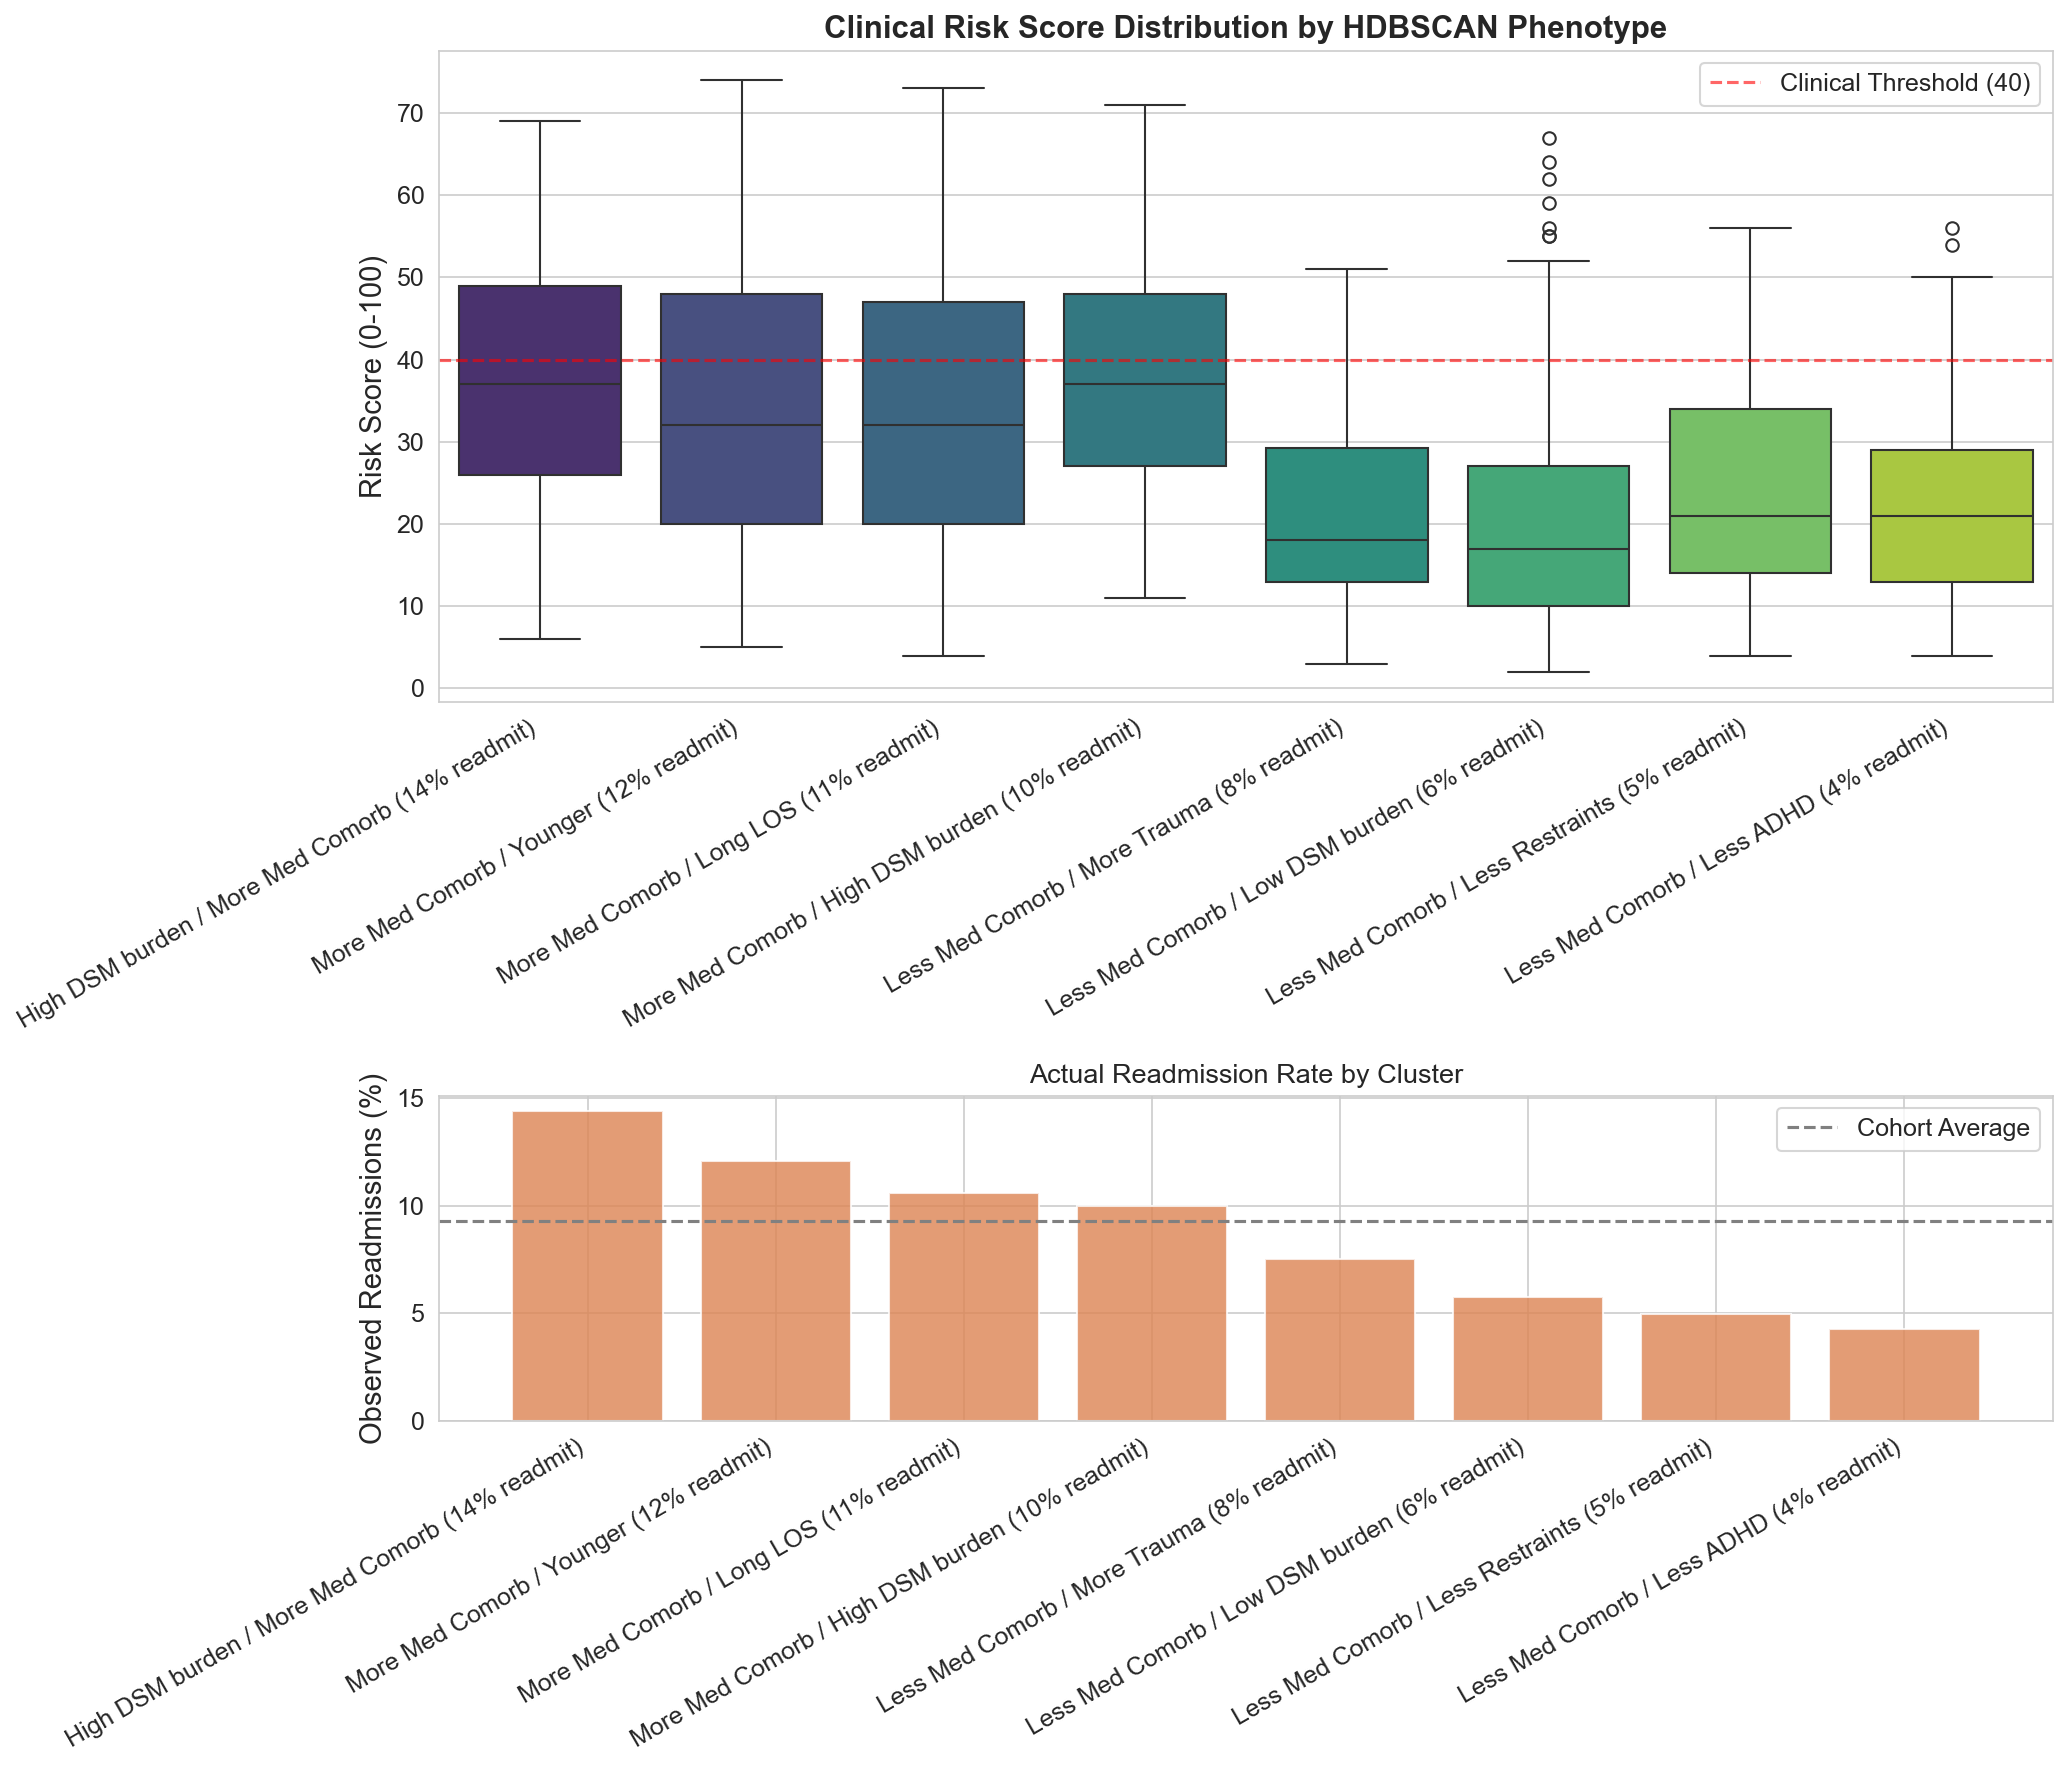

Summary of Top Risk Clusters:


,calculated_risk_score,readmitted
cluster_name,,
High DSM burden / More Med Comorb (14% readmit),37.482,0.144
More Med Comorb / Younger (12% readmit),33.897,0.121
More Med Comorb / Long LOS (11% readmit),33.697,0.106
More Med Comorb / High DSM burden (10% readmit),37.959,0.100
Less Med Comorb / More Trauma (8% readmit),21.725,0.075
Less Med Comorb / Low DSM burden (6% readmit),19.945,0.058
Less Med Comorb / Less Restraints (5% readmit),23.894,0.050
Less Med Comorb / Less ADHD (4% readmit),22.095,0.043


In [38]:
# Ensure cluster and score information is present in the dataframe
mdf_r = model_df_unscaled.copy().reset_index(drop=True)
mdf_r['cluster'] = cluster_labels
mdf_r['calculated_risk_score'] = scores
mdf_r['cluster_name'] = mdf_r['cluster'].map(cluster_names)

# Filter out noise for a cleaner visualization of distinct phenotypes
plot_clusters = mdf_r[mdf_r['cluster'] != -1].copy()

# Sort clusters by their observed readmission rate to see the trend
cluster_order = plot_clusters.groupby('cluster_name')['readmitted'].mean().sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), gridspec_kw={'height_ratios': [2, 1]})

# 1. Distribution of Risk Scores by Cluster
sns.boxplot(data=plot_clusters, x='cluster_name', y='calculated_risk_score',
            order=cluster_order, palette='viridis', ax=ax1)
ax1.axhline(40, color='red', linestyle='--', alpha=0.6, label='Clinical Threshold (40)')
ax1.set_title('Clinical Risk Score Distribution by HDBSCAN Phenotype', fontsize=15, fontweight='bold')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
ax1.set_ylabel('Risk Score (0-100)')
ax1.set_xlabel('')
ax1.legend()

# 2. Observed Readmission Rate by Cluster
cluster_stats = plot_clusters.groupby('cluster_name')['readmitted'].mean() * 100
cluster_stats = cluster_stats.reindex(cluster_order)

ax2.bar(cluster_stats.index, cluster_stats.values, color='#DD8452', alpha=0.8)
ax2.axhline(df['readmitted'].mean() * 100, color='gray', linestyle='--', label='Cohort Average')
ax2.set_ylabel('Observed Readmissions (%)')
ax2.set_title('Actual Readmission Rate by Cluster', fontsize=13)
ax2.set_xticklabels(cluster_stats.index, rotation=30, ha='right')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/Fig_Cluster_Risk_Validation.png')
plt.show()

print("Summary of Top Risk Clusters:")
display(plot_clusters.groupby('cluster_name').agg({
    'calculated_risk_score': 'mean',
    'readmitted': 'mean'
}).sort_values('readmitted', ascending=False).round(3))

In [39]:
# ── Staffing Requirement Simulation ──────────────────────────────────────────

# Assumptions based on typical inpatient psychiatric unit workflow:
# 1. Total annual admissions in this simulation context: 2,652
# 2. A 'full' review and intensive follow-up for a high-risk patient takes ~4 hours of clinical time per admission.
# 3. An FTE (Full Time Equivalent) works ~1,800 hours/year.

admissions_per_year = 2652
hours_per_review = 4
hours_per_fte = 1800

results = []
for t in [40, 50, 55]:
    flag_rate = threshold_df.loc[threshold_df['Threshold'] == t, 'Flag Rate (%)'].values[0] / 100
    catch_rate = threshold_df.loc[threshold_df['Threshold'] == t, 'Sensitivity (%)'].values[0]

    n_flagged = admissions_per_year * flag_rate
    total_hours_needed = n_flagged * hours_per_review
    fte_required = total_hours_needed / hours_per_fte

    results.append({
        'Threshold': t,
        'Readmissions Caught (%)': f'{catch_rate:.1f}%',
        'Annual Flagged Patients': int(n_flagged),
        'Clinical Hours Needed': int(total_hours_needed),
        'FTEs Required': round(fte_required, 2)
    })

staffing_df = pd.DataFrame(results)
print("--- Staffing Requirements: Transition-of-Care Simulation ---")
display(staffing_df)

--- Staffing Requirements: Transition-of-Care Simulation ---


,Threshold,Readmissions Caught (%),Annual Flagged Patients,Clinical Hours Needed,FTEs Required
0,40,73.2%,767,3068,1.70
1,50,52.8%,411,1644,0.91
2,55,39.4%,260,1040,0.58


### **Threshold Analysis Summary**

The bullet summary below is generated directly from `threshold_df` (the risk-score sweep
above), so it always reflects the current model rather than transcribed values.

In [40]:
# ── Threshold analysis summary — generated from threshold_df (never hard-coded) ─
baseline = df_scored['readmitted'].mean() * 100
print("Threshold Analysis Summary  (derived from the risk-score sweep above)")
print(f"Cohort baseline readmission rate: {baseline:.1f}%\n")

for t in (40, 50):
    row = threshold_df.loc[threshold_df['Threshold'] == t]
    if row.empty:
        print(f"\u2022 Threshold {t}: not present in threshold_df.")
        continue
    r = row.iloc[0]
    print(
        f"\u2022 Threshold {t}: flags {r['Flag Rate (%)']:.0f}% of admissions "
        f"({int(r['Total Flagged'])} charts) and captures {r['Sensitivity (%)']:.0f}% of "
        f"readmissions (sensitivity), at {r['Precision (%)']:.0f}% precision and "
        f"{r['Specificity (%)']:.0f}% specificity."
    )

print("\nWhich flagging volume best matches your transition-of-care team's capacity?")

Threshold Analysis Summary  (derived from the risk-score sweep above)
Cohort baseline readmission rate: 9.3%

• Threshold 40: flags 29% of admissions (767 charts) and captures 73% of readmissions (sensitivity), at 23% precision and 76% specificity.
• Threshold 50: flags 15% of admissions (411 charts) and captures 53% of readmissions (sensitivity), at 32% precision and 88% specificity.

Which flagging volume best matches your transition-of-care team's capacity?
